# Práctica: segmentación de clientes con K-means
**Materia:** Tópicos de Big Data · **Duración sugerida:** 90–120 minutos

## Objetivo
Construir segmentos de clientes a partir de **dos variables**, aplicar logaritmo natural y `StandardScaler()`, comparar inercia y silueta para elegir k e interpretar los grupos en sus unidades originales.

**Pregunta de negocio:** ¿qué grupos de clientes se distinguen por cuántas compras realizan y cuánto gastan?

Esta es una práctica guiada y resuelta. Ejecuta las celdas en orden y contesta las preguntas del cierre. No requiere GPU. Aunque el archivo contiene cientos de miles de líneas, agregaremos por cliente antes de calcular distancias.

## 1. Preparación y carga
En Jupyter o Google Colab, coloca `online_retail_limpios.csv` junto al notebook. También se busca en `data/processed` y `../data/processed`. En Colab puedes subir el archivo desde el panel de archivos. Ajusta `RUTA` si lo guardas en otra ubicación.

Si faltan bibliotecas, ejecuta en una celda: `%pip install numpy pandas matplotlib scikit-learn` y reinicia el kernel. El CSV es la fuente de datos de esta práctica. No contiene instrucciones para ejecutar.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from IPython.display import display, Markdown

SEED = 42
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 13, 'axes.labelsize': 11})
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

RUTA = Path('online_retail_limpios.csv')
candidatas = [RUTA, Path('data/processed') / RUTA.name,
              Path('../data/processed') / RUTA.name]
# Ruta de la fuente original; solo se usa si está disponible en este equipo.
candidatas.append(Path('/Users/lizette/Coding/bigdata/U4_1_clustering/data/processed/online_retail_limpios.csv'))
ruta = next((p for p in candidatas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError('Coloca el CSV junto al notebook o ajusta RUTA.')
df = pd.read_csv(ruta, dtype={'CustomerID': 'string', 'InvoiceNo': 'string'})
df = df.loc[:, ~df.columns.str.startswith('Unnamed:')]
print(f'Líneas: {len(df):,}; columnas: {df.shape[1]}')
display(df.head())

Python: 3.12.0 | pandas: 2.3.1 | scikit-learn: 1.7.1
Líneas: 301,022; columnas: 11


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,FechaInvoice,HoraInvoice,Monto_linea
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010-12-01,08:26:00,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,08:26:00,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010-12-01,08:26:00,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,08:26:00,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010-12-01,08:26:00,20.34


## 2. Unidad de análisis y selección de variables
Una fila original es una **línea de factura**, no un cliente ni una compra completa. Agrupamos por `CustomerID`:

| Variable del modelo | Definición | Razón de selección |
|---|---|---|
| Frecuencia | Número de `InvoiceNo` distintos por cliente | Representa la repetición de compra. Contar líneas inflaría la frecuencia. |
| Gasto total | Suma de `Quantity × UnitPrice` por cliente | Resume el valor monetario observado. |

Son las **únicas dos entradas de K-means**. Los identificadores no se utilizan como variables numéricas. Las variables pueden estar correlacionadas: más compras suelen producir más gasto.

Trabajaremos con ventas positivas e identificadas, excluyendo cancelaciones cuyo número empieza con C. Se comprueba el importe proporcionado y se recalcula para mantener una definición explícita. No quitamos valores extremos válidos ni duplicados de forma automática: pueden representar compras reales. El archivo ya fue limpiado antes de esta práctica; los resultados describen únicamente su población conservada.

In [2]:
requeridas = {'CustomerID', 'InvoiceNo', 'Quantity', 'UnitPrice', 'InvoiceDate'}
assert requeridas.issubset(df.columns), 'Faltan columnas necesarias.'
for col in ['Quantity', 'UnitPrice']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
fechas = pd.to_datetime(df['InvoiceDate'], errors='coerce')
importe = df['Quantity'] * df['UnitPrice']
valida = (df['CustomerID'].notna() & df['CustomerID'].str.strip().ne('')
          & df['InvoiceNo'].notna() & df['InvoiceNo'].str.strip().ne('')
          & ~df['InvoiceNo'].str.upper().str.startswith('C', na=False)
          & df['Quantity'].gt(0) & df['UnitPrice'].gt(0)
          & np.isfinite(importe))
ventas = df.loc[valida].copy()
ventas['Importe'] = importe.loc[valida]
if 'Monto_linea' in ventas:
    coincide = np.isclose(pd.to_numeric(ventas['Monto_linea'], errors='coerce'), ventas['Importe'])
    print(f'Coincidencia con Monto_linea: {coincide.mean():.2%}')
print(f'Conservadas: {len(ventas):,}; excluidas: {len(df)-len(ventas):,}')
print('Periodo observado:', fechas.min(), 'a', fechas.max())
clientes = ventas.groupby('CustomerID').agg(
    Frecuencia=('InvoiceNo', 'nunique'), Gasto_total=('Importe', 'sum'))
variables = ['Frecuencia', 'Gasto_total']
assert (clientes[variables] > 0).all().all()
assert np.isfinite(clientes[variables].to_numpy()).all()
print(f'Clientes para segmentar: {len(clientes):,}')
display(clientes.describe().round(2))

Coincidencia con Monto_linea: 100.00%
Conservadas: 301,022; excluidas: 0
Periodo observado: 2010-12-01 08:26:00 a 2011-12-09 12:50:00
Clientes para segmentar: 4,304


,Frecuencia,Gasto_total
count,4304.00,4304.00
mean,4.23,1822.20
std,7.53,8354.32
min,1.00,3.75
25%,1.00,255.81
50%,2.00,576.80
75%,5.00,1429.63
max,201.00,257518.90


## 3. Distribuciones originales y logaritmo natural
El gasto y la frecuencia suelen tener asimetría positiva. El logaritmo comprime las diferencias multiplicativas: pasar de 1 a 10 tiene la misma distancia logarítmica que pasar de 10 a 100.

Aplicamos **`np.log(x)` = ln(x)**. Todos los valores agregados son positivos, por lo que no necesitamos `log1p`. El logaritmo es una transformación de distribución; no garantiza normalidad estadística ni elimina los extremos.

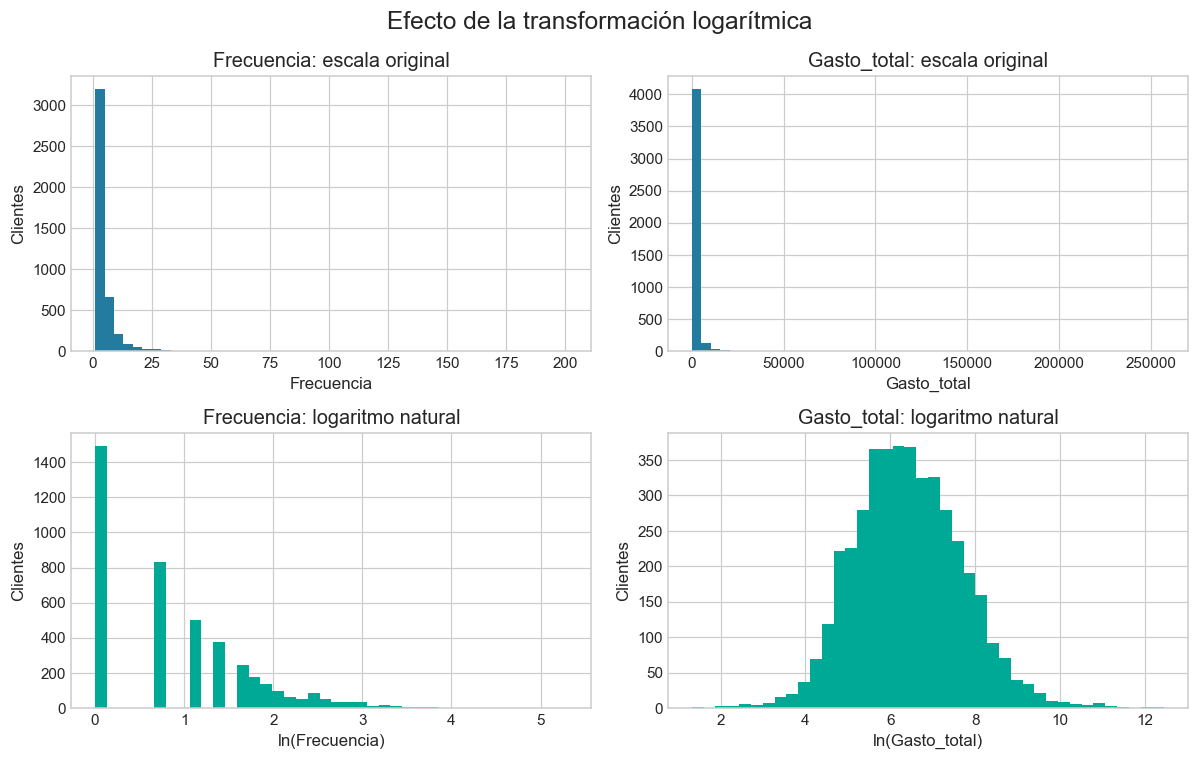

,Asimetría original,Asimetría después de ln
Frecuencia,11.838,0.784
Gasto_total,19.711,0.311


In [3]:
X_log = np.log(clientes[variables])
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, col in enumerate(variables):
    axes[0, j].hist(clientes[col], bins=50, color='#247BA0')
    axes[0, j].set(title=f'{col}: escala original', xlabel=col, ylabel='Clientes')
    axes[1, j].hist(X_log[col], bins=40, color='#00A896')
    axes[1, j].set(title=f'{col}: logaritmo natural', xlabel=f'ln({col})', ylabel='Clientes')
fig.suptitle('Efecto de la transformación logarítmica', fontsize=16)
fig.tight_layout()
plt.show()
display(pd.DataFrame({'Asimetría original': clientes[variables].skew(),
                      'Asimetría después de ln': X_log.skew()}).round(3))

## 4. Estandarización después del logaritmo
Para cada variable transformada, `StandardScaler()` calcula \(z=(\ln(x)-\mu)/\sigma\), con media y desviación de la muestra de clientes usada para ajustar el escalador (desviación con `ddof=0`). Así ambas variables tienen media aproximadamente 0 y desviación aproximadamente 1.

**Orden:** agregación por cliente → ln → StandardScaler → K-means. La distancia euclidiana y todos los indicadores se calculan en este espacio. No agregamos columnas al modelo. Es un análisis descriptivo de toda la población observada; para asignar clientes futuros se deben reutilizar este escalador y este modelo ya ajustados.

,Media,Desviación (ddof=0)
Frecuencia,0.0,1.0
Gasto_total,0.0,1.0


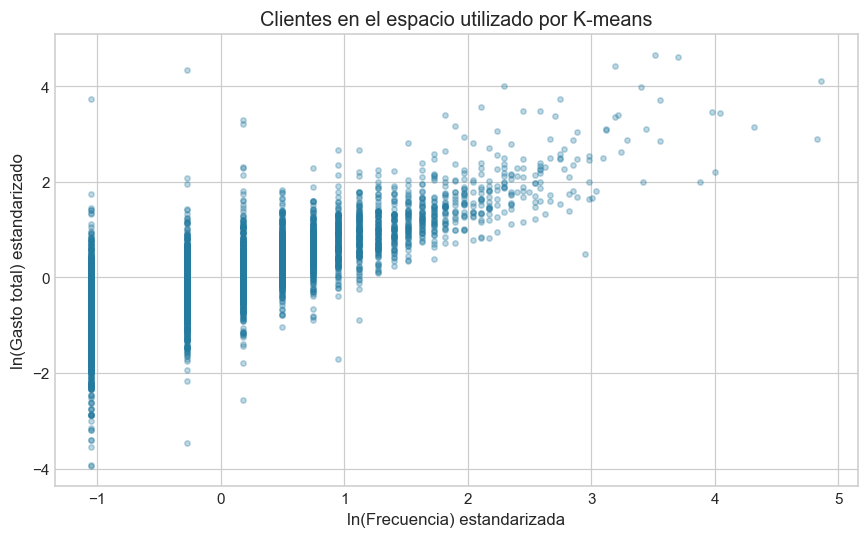

In [4]:
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
display(pd.DataFrame({'Media': X.mean(axis=0), 'Desviación (ddof=0)': X.std(axis=0)}, index=variables).round(6))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X[:, 0], X[:, 1], s=12, alpha=.3, color='#247BA0')
ax.set(title='Clientes en el espacio utilizado por K-means',
       xlabel='ln(Frecuencia) estandarizada', ylabel='ln(Gasto total) estandarizado')
plt.tight_layout()
plt.show()

## 5. ¿Cuántos segmentos? Inercia y silueta
**Inercia:** suma de distancias euclidianas al cuadrado de cada cliente a su centroide. Menor es mejor, pero siempre disminuye o se mantiene al aumentar k. Buscamos un *codo*: a partir de cierto k, la mejora adicional se reduce.

**Silueta:** para cada cliente, \(s=(b-a)/\max(a,b)\), donde a es su distancia media a su propio grupo y b la menor distancia media a otro grupo. Se mueve entre −1 y 1. Valores mayores indican mejor separación; valores negativos sugieren una asignación ambigua. No se define para k=1.

Probamos k=1…10 para inercia y k=2…10 para silueta. Fijamos semilla y `n_init=20` para reducir dependencia de una sola inicialización. La silueta se calcula con todos los clientes de este archivo. En poblaciones mucho mayores conviene una muestra fija y declarada porque su coste es cuadrático.

**Regla reproducible:** elegir el k con mayor silueta entre los candidatos y contrastarlo con el codo y el tamaño de los segmentos. No existe un k universalmente óptimo ni un umbral de silueta que garantice utilidad de negocio.

k seleccionado por silueta: 2; silueta = 0.5191


,Inercia,Silueta,Reducción inercia (%)
k,,,
1,8608.0000,NaN,NaN
2,3398.1387,0.5191,60.5235
3,2162.0149,0.4528,36.3765
4,1645.3075,0.4174,23.8993
5,1312.7863,0.4193,20.2103
6,1095.8102,0.4104,16.5279
7,953.0557,0.4139,13.0273
8,833.6280,0.4103,12.5310
9,743.0661,0.4168,10.8636


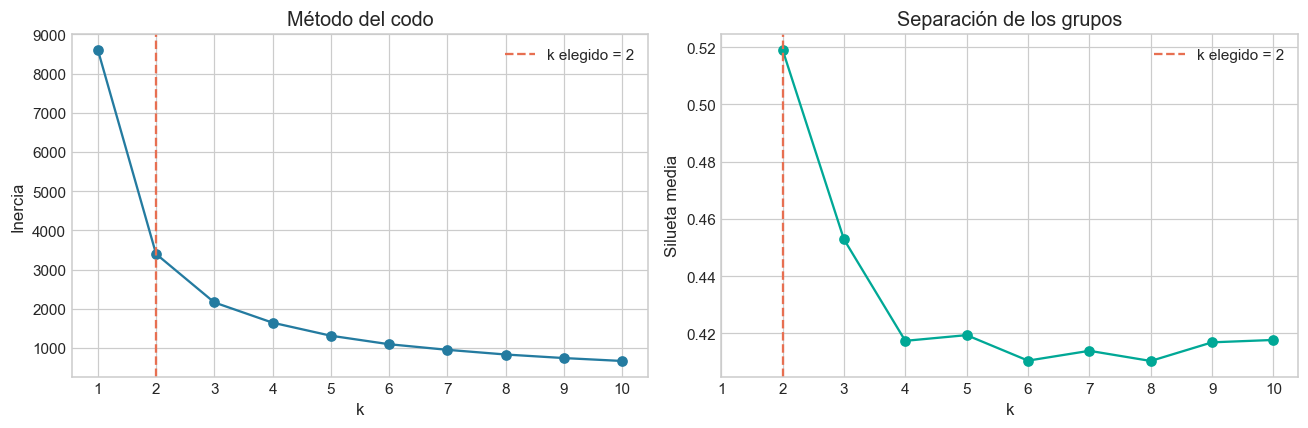

In [5]:
ks = list(range(1, min(10, len(clientes)-1) + 1))
modelos, registros = {}, []
for k in ks:
    modelo_k = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    etiquetas = modelo_k.fit_predict(X)
    modelos[k] = modelo_k
    registros.append({'k': k, 'Inercia': modelo_k.inertia_,
                      'Silueta': silhouette_score(X, etiquetas) if k > 1 else np.nan})
metricas = pd.DataFrame(registros).set_index('k')
metricas['Reducción inercia (%)'] = -metricas['Inercia'].pct_change() * 100
k_elegido = int(metricas['Silueta'].idxmax())
display(metricas.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(metricas.index, metricas['Inercia'], 'o-', color='#247BA0')
axes[0].set(title='Método del codo', xlabel='k', ylabel='Inercia')
axes[1].plot(metricas.index, metricas['Silueta'], 'o-', color='#00A896')
axes[1].set(title='Separación de los grupos', xlabel='k', ylabel='Silueta media')
for ax in axes:
    ax.set_xticks(ks)
    ax.axvline(k_elegido, color='#E76F51', linestyle='--', label=f'k elegido = {k_elegido}')
    ax.legend()
plt.tight_layout()
plt.show()
print(f'k seleccionado por silueta: {k_elegido}; silueta = {metricas.loc[k_elegido, "Silueta"]:.4f}')

## 6. Ajuste final y visualización de los segmentos
Los números de clúster que produce K-means son arbitrarios. Para facilitar su lectura, renombramos S1, S2, … en orden ascendente del gasto mediano. Estos nombres no añaden variables ni cambian las asignaciones.

La figura izquierda muestra las distancias utilizadas por el algoritmo. La derecha muestra frecuencia y gasto originales con ejes logarítmicos, para que se aprecien los clientes de mayor valor. Los centroides se calculan en el espacio estandarizado; al invertir las transformaciones se obtienen centros geométricos, no medias aritméticas del gasto original.

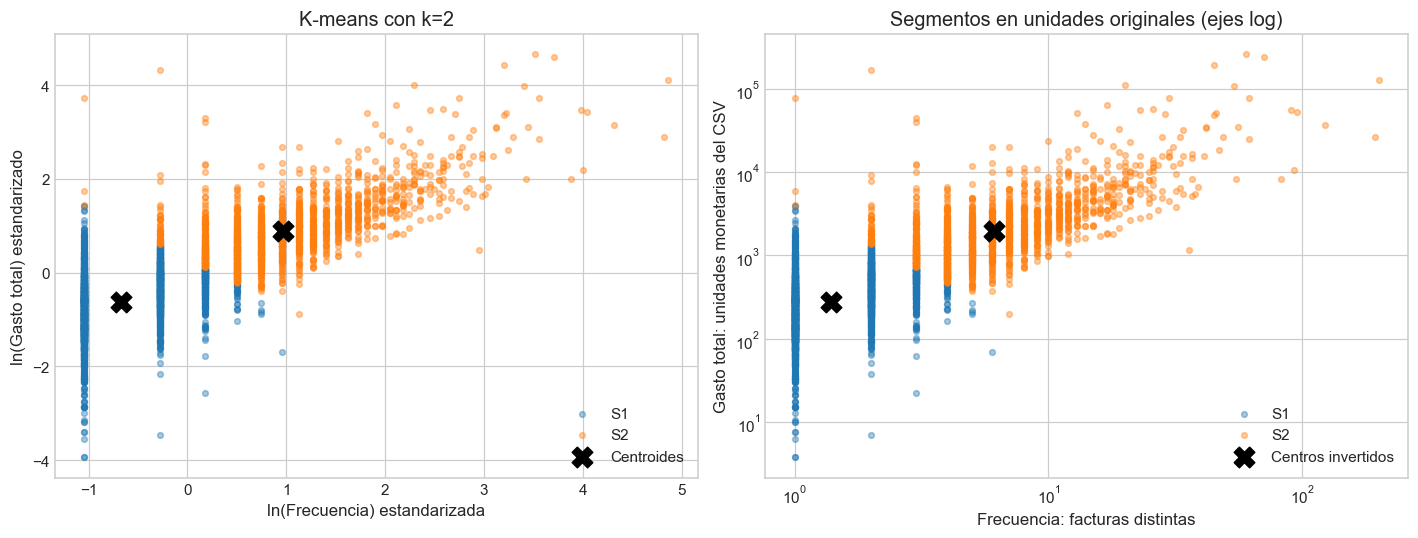

In [6]:
modelo = modelos[k_elegido]
clientes['Cluster'] = modelo.labels_
orden = clientes.groupby('Cluster')['Gasto_total'].median().sort_values().index
nombres = {int(c): f'S{i+1}' for i, c in enumerate(orden)}
clientes['Segmento'] = clientes['Cluster'].map(nombres)
centros_originales = np.exp(scaler.inverse_transform(modelo.cluster_centers_))
colores = plt.get_cmap('tab10')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for i, c in enumerate(orden):
    mask = clientes['Cluster'].to_numpy() == c
    axes[0].scatter(X[mask, 0], X[mask, 1], s=14, alpha=.4, color=colores(i), label=nombres[c])
    axes[1].scatter(clientes.loc[mask, 'Frecuencia'], clientes.loc[mask, 'Gasto_total'],
                    s=14, alpha=.4, color=colores(i), label=nombres[c])
axes[0].scatter(*modelo.cluster_centers_.T, marker='X', s=180, c='black', label='Centroides')
axes[1].scatter(*centros_originales.T, marker='X', s=180, c='black', label='Centros invertidos')
axes[0].set(title=f'K-means con k={k_elegido}', xlabel='ln(Frecuencia) estandarizada', ylabel='ln(Gasto total) estandarizado')
axes[1].set(xscale='log', yscale='log', title='Segmentos en unidades originales (ejes log)',
            xlabel='Frecuencia: facturas distintas', ylabel='Gasto total: unidades monetarias del CSV')
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

## 7. Validar la separación y describir los perfiles
El gráfico de silueta muestra la dispersión dentro de cada segmento. Una buena media puede ocultar clientes ambiguos. Revisamos también los tamaños y los porcentajes de siluetas negativas.

El resumen utiliza medianas y cuartiles para describir al cliente típico, además de la contribución al gasto observado. No inferimos una moneda a partir del nombre del archivo.

,Clientes,Frecuencia_mediana,Gasto_mediano,Gasto_Q1,Gasto_Q3,Gasto_suma,Silueta_media,Negativas_pct,Clientes_pct,Gasto_pct
Segmento,,,,,,,,,,
S1,2540,1.0,298.42,164.60,496.73,950000.49,0.55,0.24,59.01,12.11
S2,1764,5.0,1704.96,1051.55,3119.32,6892766.25,0.47,0.23,40.99,87.89


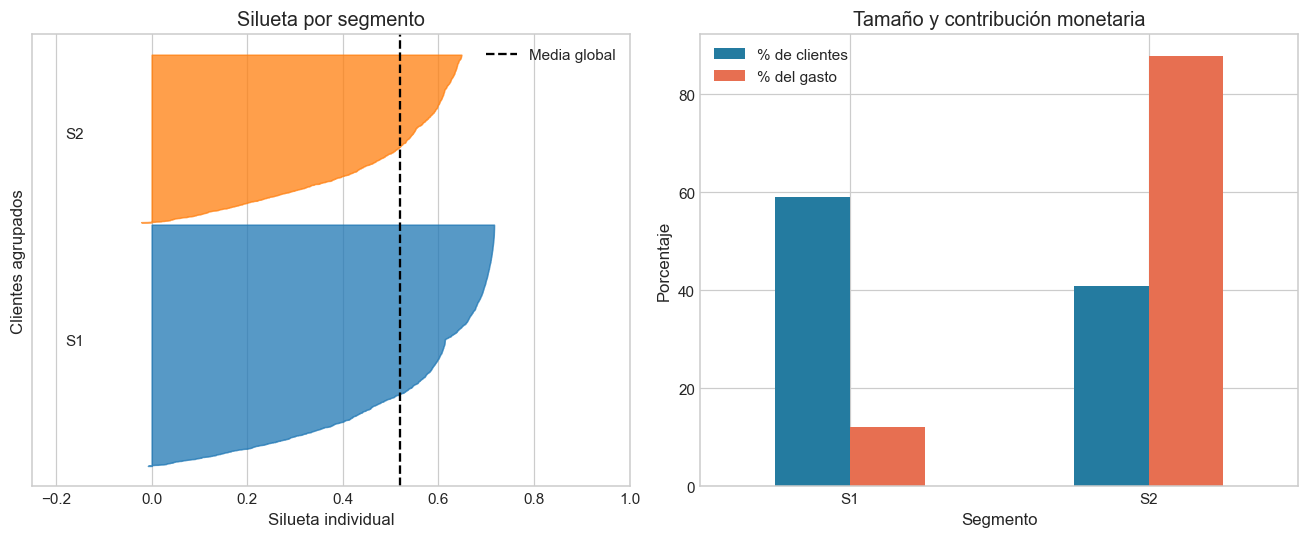

In [7]:
s_individual = silhouette_samples(X, modelo.labels_)
clientes['Silueta'] = s_individual
perfil = clientes.groupby('Segmento').agg(
    Clientes=('Frecuencia', 'size'), Frecuencia_mediana=('Frecuencia', 'median'),
    Gasto_mediano=('Gasto_total', 'median'), Gasto_Q1=('Gasto_total', lambda s: s.quantile(.25)),
    Gasto_Q3=('Gasto_total', lambda s: s.quantile(.75)), Gasto_suma=('Gasto_total', 'sum'),
    Silueta_media=('Silueta', 'mean'), Negativas_pct=('Silueta', lambda s: (s < 0).mean()*100))
perfil['Clientes_pct'] = perfil['Clientes'] / len(clientes) * 100
perfil['Gasto_pct'] = perfil['Gasto_suma'] / clientes['Gasto_total'].sum() * 100
display(perfil.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
inicio = 0
for i, c in enumerate(orden):
    valores = np.sort(s_individual[modelo.labels_ == c])
    fin = inicio + len(valores)
    axes[0].fill_betweenx(np.arange(inicio, fin), 0, valores, color=colores(i), alpha=.75)
    axes[0].text(-.18, (inicio+fin)/2, nombres[c])
    inicio = fin + 25
axes[0].axvline(s_individual.mean(), color='black', linestyle='--', label='Media global')
axes[0].set(xlim=(-.25, 1), yticks=[], xlabel='Silueta individual', ylabel='Clientes agrupados', title='Silueta por segmento')
axes[0].legend()
perfil[['Clientes_pct', 'Gasto_pct']].plot.bar(ax=axes[1], color=['#247BA0', '#E76F51'], rot=0)
axes[1].set(title='Tamaño y contribución monetaria', xlabel='Segmento', ylabel='Porcentaje')
axes[1].legend(['% de clientes', '% del gasto'])
plt.tight_layout()
plt.show()
assert perfil['Clientes'].sum() == len(clientes)
assert np.isclose(perfil['Gasto_suma'].sum(), ventas['Importe'].sum())

## 8. Actividades para entregar
1. Explica por qué se cuentan facturas distintas y no líneas del CSV.
2. Compara la asimetría antes y después de ln. ¿Por qué estandarizamos después?
3. Señala visualmente un posible codo y contrástalo con el k de mayor silueta. Cita al menos dos valores de la tabla. Si discrepan, explica el compromiso entre separación y detalle.
4. Elige otro k de la tabla, repite el perfilado y compara el tamaño y la interpretabilidad de sus segmentos. ¿Mejora la utilidad aunque su silueta sea menor?
5. Propón una acción comercial por segmento y explica qué información adicional necesitarías para validarla.

**Criterios sugeridos (100 puntos):** preparación y agregación 20; explicación de ln y escalado 20; selección de k con evidencia 25; lectura de gráficas 15; interpretación y limitaciones 20.

## 9. Interpretación final de los segmentos
El siguiente cierre se genera con los resultados calculados, no con perfiles supuestos. Los niveles de frecuencia y gasto son relativos a las medianas de esta población.

**Lectura del codo para el archivo proporcionado:** pasar de k=1 a k=2 reduce la inercia 60.52%; de 2 a 3, 36.38%; y de 3 a 4, 23.90%. El codo no es tajante: hay ganancias adicionales, especialmente con k=3. Se elige k=2 porque obtiene la mayor silueta (0.519 frente a 0.453 con k=3), mantiene dos grupos de tamaño sustancial y ofrece una segmentación inicial fácil de interpretar. Estos valores corresponden a la ejecución guardada; si cambias los datos, vuelve a contrastarlos con la tabla.


In [8]:
med_f = clientes['Frecuencia'].median()
med_g = clientes['Gasto_total'].median()
texto = [f'### Resultado con k={k_elegido}',
         f'Se segmentaron **{len(clientes):,} clientes**. La silueta media es **{s_individual.mean():.3f}**. '
         f'La selección maximiza la silueta entre k=2 y k={max(ks)}. '
         'La curva de inercia permite evaluar cuánto detalle adicional se gana al aumentar k.']
for seg, r in perfil.iterrows():
    nivel_f = 'mayor' if r.Frecuencia_mediana > med_f else ('menor' if r.Frecuencia_mediana < med_f else 'igual')
    nivel_g = 'mayor' if r.Gasto_mediano > med_g else ('menor' if r.Gasto_mediano < med_g else 'igual')
    if nivel_f == 'mayor' and nivel_g == 'mayor':
        accion = 'Priorizar retención, beneficios por recurrencia y atención personalizada.'
    elif nivel_f != 'mayor' and nivel_g == 'mayor':
        accion = 'Explorar incentivos para una segunda compra o una mayor recurrencia.'
    elif nivel_f == 'mayor':
        accion = 'Explorar venta complementaria y ofertas que eleven el valor por compra.'
    else:
        accion = 'Explorar campañas de segunda compra y recomendaciones de productos.'
    texto.append(f'**{seg}.** Reúne {int(r.Clientes):,} clientes ({r.Clientes_pct:.1f}%) y aporta '
                 f'{r.Gasto_pct:.1f}% del gasto. Su cliente típico realiza **{r.Frecuencia_mediana:g} compras** '
                 f'y acumula **{r.Gasto_mediano:,.2f} unidades monetarias** '
                 f'(cuartiles de gasto: {r.Gasto_Q1:,.2f}–{r.Gasto_Q3:,.2f}). '
                 f'Su frecuencia mediana es {nivel_f} y su gasto mediano es {nivel_g} que la mediana global '
                 f'({med_f:g} compras y {med_g:,.2f} unidades). {accion} '
                 f'Silueta media: {r.Silueta_media:.3f}; asignaciones con silueta negativa: {r.Negativas_pct:.1f}%.')
texto.append('**Alcance de la interpretación.** Estos grupos describen compras observadas y no prueban lealtad, '
             'rentabilidad ni abandono. La frecuencia y el gasto comparten información. Los clientes incorporados '
             'al final del periodo tuvieron menos tiempo para comprar. El CSV limpiado puede excluir devoluciones '
             'u otras operaciones, por lo que el gasto analizado no equivale necesariamente al ingreso neto. '
             'Los extremos se conservaron: el logaritmo reduce su influencia, pero no la elimina. '
             'Las acciones son hipótesis para probar. K-means busca grupos compactos en el espacio transformado; '
             'una estructura continua puede dividirse sin que existan categorías naturales.')
display(Markdown('\n\n'.join(texto)))

### Resultado con k=2

Se segmentaron **4,304 clientes**. La silueta media es **0.519**. La selección maximiza la silueta entre k=2 y k=10. La curva de inercia permite evaluar cuánto detalle adicional se gana al aumentar k.

**S1.** Reúne 2,540 clientes (59.0%) y aporta 12.1% del gasto. Su cliente típico realiza **1 compras** y acumula **298.42 unidades monetarias** (cuartiles de gasto: 164.60–496.73). Su frecuencia mediana es menor y su gasto mediano es menor que la mediana global (2 compras y 576.80 unidades). Explorar campañas de segunda compra y recomendaciones de productos. Silueta media: 0.553; asignaciones con silueta negativa: 0.2%.

**S2.** Reúne 1,764 clientes (41.0%) y aporta 87.9% del gasto. Su cliente típico realiza **5 compras** y acumula **1,704.95 unidades monetarias** (cuartiles de gasto: 1,051.55–3,119.32). Su frecuencia mediana es mayor y su gasto mediano es mayor que la mediana global (2 compras y 576.80 unidades). Priorizar retención, beneficios por recurrencia y atención personalizada. Silueta media: 0.470; asignaciones con silueta negativa: 0.2%.

**Alcance de la interpretación.** Estos grupos describen compras observadas y no prueban lealtad, rentabilidad ni abandono. La frecuencia y el gasto comparten información. Los clientes incorporados al final del periodo tuvieron menos tiempo para comprar. El CSV limpiado puede excluir devoluciones u otras operaciones, por lo que el gasto analizado no equivale necesariamente al ingreso neto. Los extremos se conservaron: el logaritmo reduce su influencia, pero no la elimina. Las acciones son hipótesis para probar. K-means busca grupos compactos en el espacio transformado; una estructura continua puede dividirse sin que existan categorías naturales.